In [2]:
import sys
import torch
import torchvision
import matplotlib

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: c:\Users\vipin\Downloads\image-classification-system\.venv\Scripts\python.exe
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA: True
GPU: NVIDIA GeForce RTX 2050


In [3]:
# CIFAR-10 Dataset

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Image preprocessing
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Download CIFAR-10
train_dataset = datasets.CIFAR10(
    root="../data",
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = datasets.CIFAR10(
    root="../data",
    train=False,
    download=True,
    transform=test_transform
)

# Data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# CIFAR-10 classes
classes = train_dataset.classes

print("Classes:", classes)
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Number of classes:", len(classes))

Using device: cuda


100%|██████████| 170M/170M [00:32<00:00, 5.25MB/s] 


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 50000
Test images: 10000
Number of classes: 10


In [4]:
# Load Pre-trained MobileNetV2

from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
import torch.nn as nn

# Load ImageNet-pretrained MobileNetV2
weights = MobileNet_V2_Weights.DEFAULT
model = mobilenet_v2(weights=weights)

# Replace final classifier for CIFAR-10
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    10
)

# Move model to GPU
model = model.to(device)

print(model.classifier)
print("\nModel device:", next(model.parameters()).device)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to C:\Users\vipin/.cache\torch\hub\checkpoints\mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:01<00:00, 8.70MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=10, bias=True)
)

Model device: cuda:0


In [6]:
# Loss function and optimizer

import torch.optim as optim

# Cross-entropy loss for multi-class classification
criterion = nn.CrossEntropyLoss()

# Adam optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

# Number of training epochs
num_epochs = 5

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 0.0001)
print("Epochs:", num_epochs)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Epochs: 5


In [14]:
import copy
import time
from tqdm.auto import tqdm

c:\Users\vipin\Downloads\image-classification-system\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [15]:
# Training and evaluation functions

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(loader, desc="Training", leave=False)

    for images, labels in progress_bar:
        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        progress_bar.set_postfix(
            loss=loss.item(),
            accuracy=100 * correct / total
        )

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        progress_bar = tqdm(loader, desc="Evaluating", leave=False)

        for images, labels in progress_bar:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [16]:
# Train MobileNetV2

train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []

best_accuracy = 0.0
best_model_state = copy.deepcopy(model.state_dict())

start_time = time.time()

for epoch in range(num_epochs):

    print(f"\nEpoch {epoch + 1}/{num_epochs}")
    print("-" * 40)

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    test_loss, test_accuracy = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_accuracy:.2f}%")

    # Save best model
    if test_accuracy > best_accuracy:
        best_accuracy = test_accuracy
        best_model_state = copy.deepcopy(model.state_dict())

        print("✓ Best model updated")

total_time = time.time() - start_time

print("\nTraining completed!")
print(f"Best Test Accuracy: {best_accuracy:.2f}%")
print(f"Training Time: {total_time / 60:.2f} minutes")


Epoch 1/5
----------------------------------------


Train Loss: 0.5350
Train Accuracy: 82.71%
Test Loss: 0.2357
Test Accuracy: 92.01%
✓ Best model updated

Epoch 2/5
----------------------------------------


Train Loss: 0.2312
Train Accuracy: 92.20%
Test Loss: 0.1989
Test Accuracy: 93.17%
✓ Best model updated

Epoch 3/5
----------------------------------------


Train Loss: 0.1667
Train Accuracy: 94.30%
Test Loss: 0.1696
Test Accuracy: 94.18%
✓ Best model updated

Epoch 4/5
----------------------------------------


Train Loss: 0.1267
Train Accuracy: 95.62%
Test Loss: 0.1681
Test Accuracy: 94.37%
✓ Best model updated

Epoch 5/5
----------------------------------------


Train Loss: 0.1015
Train Accuracy: 96.49%
Test Loss: 0.1550
Test Accuracy: 94.89%
✓ Best model updated

Training completed!
Best Test Accuracy: 94.89%
Training Time: 565.17 minutes


In [17]:
# Save the best trained MobileNetV2 model

import os
import torch

# Load the best weights found during training
model.load_state_dict(best_model_state)

# Create models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

model_path = "../models/mobilenetv2_cifar10.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "architecture": "MobileNetV2",
    "num_classes": 10,
    "class_names": train_dataset.classes,
    "test_accuracy": best_accuracy,
    "epochs": num_epochs
}, model_path)

print("Model saved successfully!")
print("Path:", model_path)
print(f"Best Test Accuracy: {best_accuracy:.2f}%")

Model saved successfully!
Path: ../models/mobilenetv2_cifar10.pth
Best Test Accuracy: 94.89%


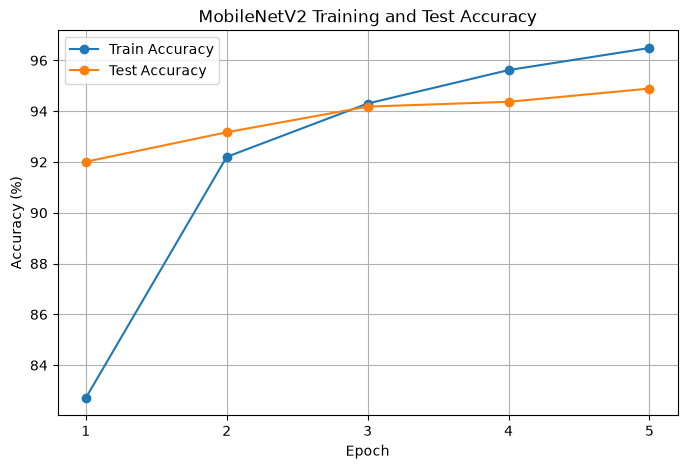

Saved: ../results/training_curves.png


In [18]:
# Plot training curves

import matplotlib.pyplot as plt
import os

os.makedirs("../results", exist_ok=True)

epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_accuracies, marker="o", label="Train Accuracy")
plt.plot(epochs_range, test_accuracies, marker="o", label="Test Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("MobileNetV2 Training and Test Accuracy")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)

plt.savefig("../results/training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved: ../results/training_curves.png")

Top-1 Accuracy: 94.89%
Top-5 Accuracy: 99.89%

Classification Report:

              precision    recall  f1-score   support

    airplane     0.9548    0.9510    0.9529      1000
  automobile     0.9787    0.9630    0.9708      1000
        bird     0.9359    0.9490    0.9424      1000
         cat     0.9039    0.8750    0.8892      1000
        deer     0.9421    0.9600    0.9510      1000
         dog     0.8980    0.9240    0.9108      1000
        frog     0.9738    0.9670    0.9704      1000
       horse     0.9755    0.9540    0.9646      1000
        ship     0.9681    0.9720    0.9701      1000
       truck     0.9596    0.9740    0.9667      1000

    accuracy                         0.9489     10000
   macro avg     0.9490    0.9489    0.9489     10000
weighted avg     0.9490    0.9489    0.9489     10000



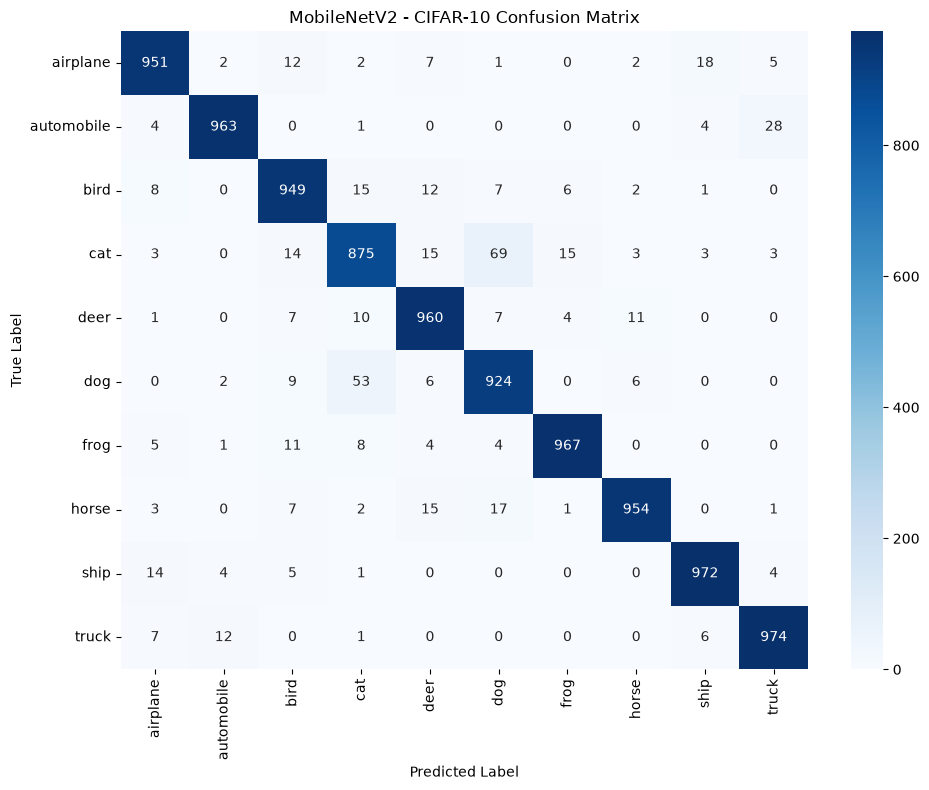


Saved: ../results/confusion_matrix.png


In [19]:
# Final model evaluation
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os
import torch

# Make sure best model is loaded
model.load_state_dict(best_model_state)
model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        # Top-1 prediction
        _, predictions = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# -------------------------
# Top-1 Accuracy
# -------------------------
top1_accuracy = np.mean(all_predictions == all_labels) * 100

# -------------------------
# Top-5 Accuracy
# -------------------------
top5_predictions = np.argsort(
    all_probabilities,
    axis=1
)[:, -5:]

top5_correct = np.array([
    label in predictions
    for label, predictions in zip(all_labels, top5_predictions)
])

top5_accuracy = np.mean(top5_correct) * 100

print("=" * 50)
print(f"Top-1 Accuracy: {top1_accuracy:.2f}%")
print(f"Top-5 Accuracy: {top5_accuracy:.2f}%")
print("=" * 50)

# -------------------------
# Classification Report
# -------------------------
class_names = test_dataset.classes

print("\nClassification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        digits=4
    )
)

# -------------------------
# Confusion Matrix
# -------------------------
cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MobileNetV2 - CIFAR-10 Confusion Matrix")

plt.tight_layout()

cm_path = "../results/confusion_matrix.png"

plt.savefig(
    cm_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", cm_path)

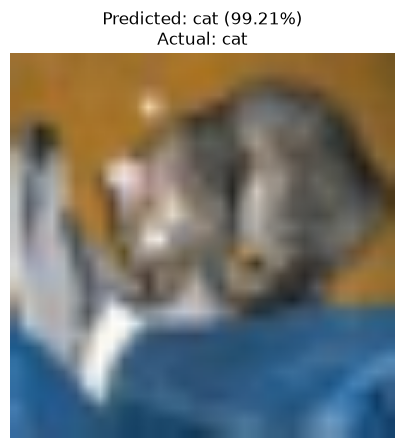

Predicted: cat
Actual: cat
Confidence: 99.21%


In [21]:
# Test model on a sample CIFAR-10 image

import torch
import matplotlib.pyplot as plt
import numpy as np

# CIFAR-10 class names
classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Get one batch from test loader
images, labels = next(iter(test_loader))

# Select first image
image = images[0]
true_label = labels[0].item()

# Prediction
model.eval()

with torch.no_grad():
    output = model(image.unsqueeze(0).to(device))
    probabilities = torch.softmax(output, dim=1)
    predicted_label = output.argmax(dim=1).item()
    confidence = probabilities[0, predicted_label].item() * 100

# Display image
img = image.cpu().permute(1, 2, 0).numpy()

# Undo normalization if your test transform uses ImageNet normalization
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

img = img * std + mean
img = np.clip(img, 0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")

plt.title(
    f"Predicted: {classes[predicted_label]} ({confidence:.2f}%)\n"
    f"Actual: {classes[true_label]}"
)

plt.show()

print("Predicted:", classes[predicted_label])
print("Actual:", classes[true_label])
print(f"Confidence: {confidence:.2f}%")